In [1]:
# Import the libraries
import xarray as xr
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import numpy as np
#Plot spectres 
from scipy import signal
from scipy import fft
import netCDF4


## Annex 3-B - Overshootings caused by bi-laplacian diffusion

## Running the simulations


To run the simulation we need to run a  traadvOFF+LAP simulation and a traadvOFF+BILAP simulation in the case of the saltblock. You can do so yourself under the experience names ```cn_exp``` = ```CANAL_saltblock_lap_traadvOFF``` and ```CANAL_saltblock_blp_traadvOFF``` __or you can execute the cell below.__

In [2]:
%%bash 

#Insert below the directory path in which you will run the simulations
#It should look like so : /.../EXP$$

DIR=/Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/tests/EXP42/EXP00
 
cd /"$DIR"

rm CANAL_saltblock_lap_traadvOFF_all_grid.nc
rm CANAL_saltblock_blp_traadvOFF_all_grid.nc

chmod -R a+x /"$DIR"/annex3_cfg/

bash /"$DIR"/annex3_cfg/annex3B.sh "$DIR"

rm: impossible de supprimer 'CANAL_saltblock_blp_traadvOFF_all_grid.nc': No such file or directory
+ set -u
+ '[' 1 -lt 1 ']'
+ DIR=/Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/tests/EXP42/EXP00
+ SRC=/Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/tests/EXP42/EXP00/namelist_cfg
+ '[' '!' -f /Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/tests/EXP42/EXP00/namelist_cfg ']'
+ SED_EXPR=(-e 's/rn_domszx.*=.*\!/rn_domszx        =       1000.    !/' -e 's/rn_domszy.*=.*\!/rn_domszy        =       1000.   !/' -e 's/rn_domszz.*=.*\!/rn_domszz        =       1000.  !/' -e 's/rn_dx.*=.*\!/rn_dx        =       20.     !/' -e 's/rn_dy.*=.*\!/rn_dy        =       20.  !/' -e 's/rn_dz.*=.*\!/rn_dz        =       1000.  !/' -e 's/rn_0xratio.*=.*\!/rn_0xratio      =       0.5  !/' -e 's/rn_0yratio.*=.*\!/rn_0yratio      =       0.5  !/' -e 's/nn_fcase.*=.*\!/nn_fcase  =       0  !/' -e 's/rn_ppgphi0.*=.*\!/rn_ppgphi0      =       38.5  !/' -e 's/rn_u10.*=.*\!/rn_u10      =       0.  !/' -e '

19,29c19,29
<    rn_domszx        =       1000.    !  x horizontal size         [km]
<    rn_domszy        =       1000.   !  y horizontal size         [km]
<    rn_domszz        =       1000.  !  z vertical size            [m]
<    rn_dx        =       20.     !  x horizontal resolution   [km]
<    rn_dy        =       20.  !  y horizontal resolution   [km]
<    rn_dz        =       1000.  !  z vertical resolution      [m]
<    rn_0xratio      =       0.5  !  x-domain ratio of the 0
<    rn_0yratio      =       0.5  !  y-domain ratio of the 0
<    nn_fcase  =       0  !  F computation (0:f0, 1:Beta, 2:real)
<    rn_ppgphi0      =       38.5  !  Reference latitude      [degrees]
<    rn_u10      =       0.  !  10m wind speed              [m/s]
---
>    rn_domszx	=	864.	!  x horizontal size         [km]
>    rn_domszy	=	1000.	!  y horizontal size         [km]
>    rn_domszz	=	1000.  !  z vertical size            [m]
>    rn_dx	=	10.	!  x horizontal resolution   [km]
>    rn_dy	=	10.  ! 

+ sed -i.bak -e 's/ln_traadv_OFF.*=.*\!/ln_traadv_OFF        =       .true.  !/' -e 's/ln_traadv_cen.*=.*\!/ln_traadv_cen        =       .false. !/' -e 's/ln_traadv_fct.*=.*\!/ln_traadv_fct        =       .false. !/' -e 's/ln_traadv_mus.*=.*\!/ln_traadv_mus        =       .false. !/' -e 's/ln_traadv_ubs.*=.*\!/ln_traadv_ubs        =       .false. !/' -e 's/ln_traadv_qck.*=.*\!/ln_traadv_qck        =       .false. !/' -e 's/nn_cen_h.*=.*\!/nn_cen_h  =       2               !/' -e 's/nn_cen_v.*=.*\!/nn_cen_v  =       2               !/' -e 's/cn_exp.*=.*'\''.*'\''/cn_exp =  '\''CANAL_saltblock_lap_traadvOFF'\''      /' -e 's/ln_traldf_OFF.*=.*\!/ln_traldf_OFF        =       .false. !/' -e 's/ln_traldf_lap.*=.*\!/ln_traldf_lap        =       .true. !/' -e 's/ln_traldf_blp.*=.*\!/ln_traldf_blp        =       .false. !/' /Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/tests/EXP42/EXP00/namelist_cfg
+ diff /Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/tests/EXP42/EXP00/namelist_cfg /Us

59c59
<    cn_exp =  'CANAL_saltblock_lap_traadvOFF'            		 !  experience name
---
>    cn_exp    =       'CANAL_saltblock'      		 !  experience name
167c167
<    ln_traadv_OFF        =       .true.  !  No tracer advection
---
>    ln_traadv_OFF        =       .true. !  No tracer advection
169,171c169,171
<       nn_cen_h  =       2               !  =2/4, horizontal 2nd order CEN / 4th order CEN
<       nn_cen_v  =       2               !  =2/4, vertical   2nd order CEN / 4th order COMPACT
<    ln_traadv_fct        =       .false. !  FCT scheme
---
>       nn_cen_h	=	4		!  =2/4, horizontal 2nd order CEN / 4th order CEN
>       nn_cen_v  =       4		!  =2/4, vertical   2nd order CEN / 4th order COMPACT
>    ln_traadv_fct        =       .false.  !  FCT scheme
184,185c184,185
<    ln_traldf_OFF        =       .false. !  No explicit diffusion
<    ln_traldf_lap        =       .true. !    laplacian operator
---
>    ln_traldf_OFF        =       .true. !  No explicit diffusion
>    ln


real	0m48.932s
user	1m54.790s
sys	0m21.739s


...

59c59
<    cn_exp =  'CANAL_saltblock_blp_traadvOFF'                  		 !  experience name
---
>    cn_exp =  'CANAL_saltblock_lap_traadvOFF'            		 !  experience name
185,186c185,186
<    ln_traldf_lap        =       .false. !    laplacian operator
<    ln_traldf_blp        =       .true. !  bilaplacian operator
---
>    ln_traldf_lap        =       .true. !    laplacian operator
>    ln_traldf_blp        =       .false. !  bilaplacian operator


+ ./run_nemo.sh

real	0m39.015s
user	1m49.839s
sys	0m17.134s



Everything looks good



+ echo Run CANAL_saltblock_blp_traadvOFF_all_grid.nc completed


Run CANAL_saltblock_blp_traadvOFF_all_grid.nc completed


In [3]:
rep = ''

In [4]:
lap_test_ = xr.open_dataset(rep+'CANAL_saltblock_lap_traadvOFF_all_grid.nc')
lap_test = lap_test_.soce
blp_test_ = xr.open_dataset(rep+'CANAL_saltblock_blp_traadvOFF_all_grid.nc')
blp_test = blp_test_.soce

In [5]:
domx = 1020
domy = 1020
dx = 20
dy = 20
sx = 250//dx//2
sy = 250//dy//2

x0 = domx//dx//2
y0 = domy//dy//2

t0 = 900*24*3600
dt = 900*24*3600
v = 0.5

salt_ref = np.ones(shape = (domy//dy, domx//dx))*30 
salt_ref[y0-sy:y0+sy+1, x0 - sx: x0+sx +1] = 35

In [6]:
ref = salt_ref[:,25]

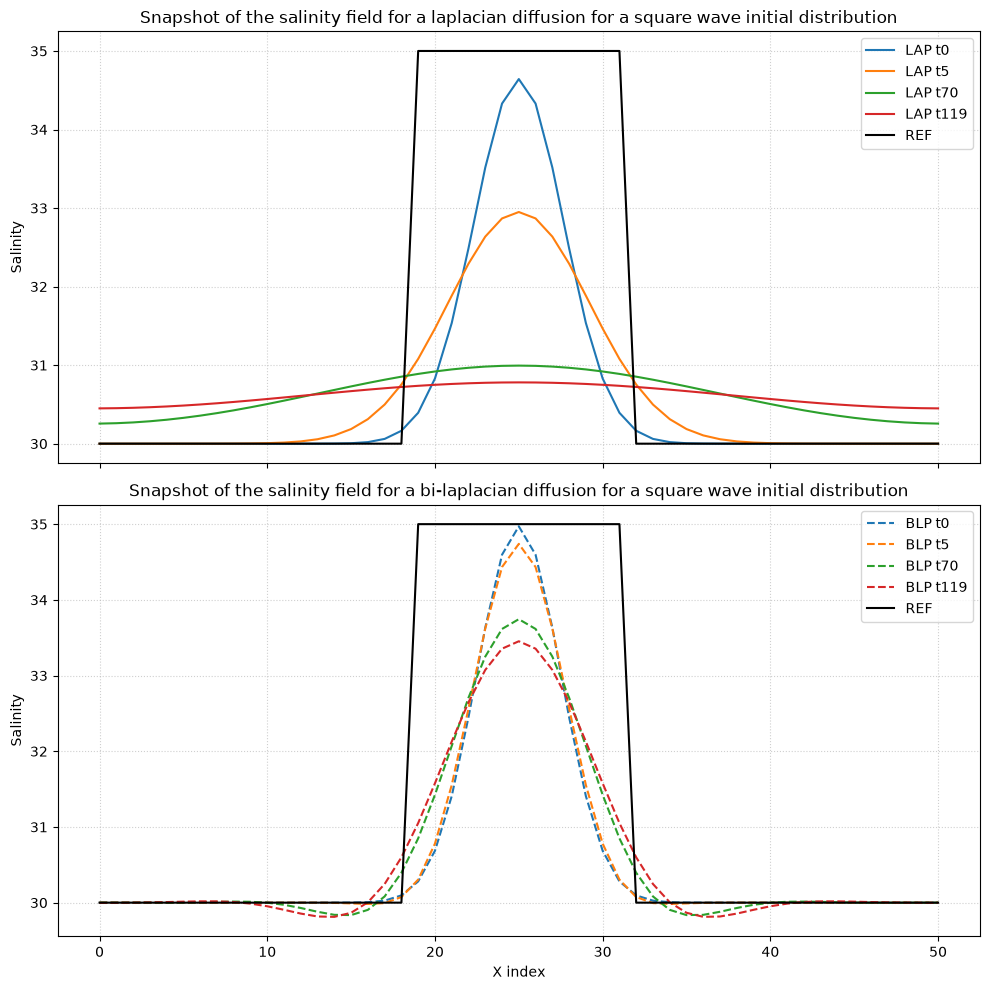

In [7]:
time_indices = [0, 5, 70, 119]
configs = [
    (lap_test, 'LAP', 'laplacian', '-'),
    (blp_test, 'BLP', 'bi-laplacian', '--')
]


fig, axes = plt.subplots(2, 1, figsize=(10, 10), sharex=True)


for ax, (data, prefix, diff_type, ls) in zip(axes, configs):

    sliced_data = data.isel(y_grid_T=25, deptht=0)
    

    for t in time_indices:
        ax.plot(sliced_data.isel(time_counter=t), linestyle=ls, label=f'{prefix} t{t}')
    

    ax.plot(ref, color='black', linestyle='-', label='REF', linewidth=1.5)

    ax.set_title(f'Snapshot of the salinity field for a {diff_type} diffusion for a square wave initial distribution')
    ax.set_ylabel('Salinity')
    ax.legend(loc='upper right')
    ax.grid(True, linestyle=':', alpha=0.6)

axes[1].set_xlabel('X index')
plt.tight_layout()
plt.show()

Overshoot/undershoot for bilaplacian and not for laplacian.

(120, 2, 51, 51)


Text(0.5, 0, 't')

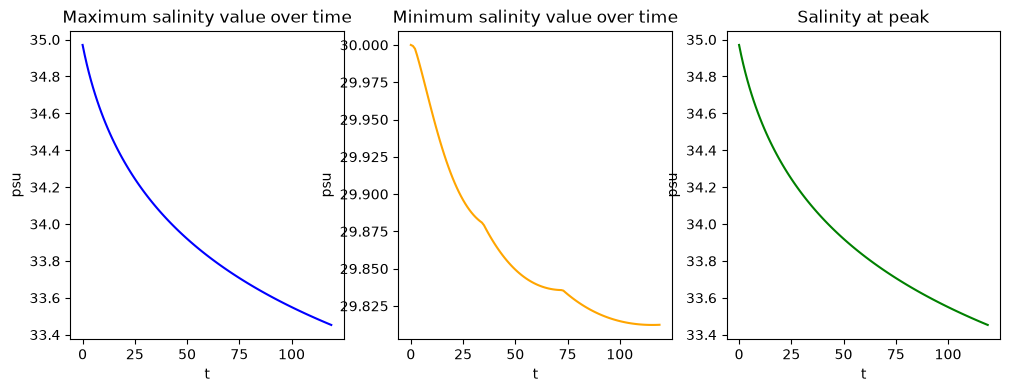

In [8]:
overshoot = []
undershoot = []
MID =[]
print(blp_test.shape)
fig, axes = plt.subplots(1,3, figsize=(12,4))
for t in range (blp_test.shape[0]):
    max = blp_test.isel(deptht=0, time_counter=t, y_grid_T = 25).max()
    min = blp_test.isel(deptht=0, time_counter=t, y_grid_T = 25).min()
    mid = blp_test.isel(deptht=0, time_counter=t, x_grid_T = 25, y_grid_T = 25)
    overshoot.append(max)
    undershoot.append(min)
    MID.append(mid)
axes[0].plot(overshoot, color = 'blue')
axes[0].set_title('Maximum salinity value over time')
axes[0].set_ylabel('psu')
axes[0].set_xlabel('t')

axes[1].plot(undershoot, color = 'orange')
axes[1].set_title('Minimum salinity value over time')
axes[1].set_ylabel('psu')
axes[1].set_xlabel('t')

axes[2].plot(MID, color = 'green')
axes[2].set_title('Salinity at peak')
axes[2].set_ylabel('psu')
axes[2].set_xlabel('t')